# Chapter 2 — Fundamental Concepts: How Do Machines Learn?
### Reproduction & Theoretical Deep-Dive — *grokking Deep Learning* (Manning)

Chapter 2 of the book is also **conceptual**. It lays out the vocabulary used for the rest of the
book: what "learning" means for a machine, and the two big ways of classifying learning methods —
**supervised vs unsupervised** and **parametric vs non-parametric**.

The explanations below are my own. The small demos use scikit-learn on toy data and were
**added by me** (they are not code from the book) so that each definition can be seen, not just read.

**Roadmap**
1. What does it mean for a machine to learn?
2. Supervised learning (+ demo)
3. Unsupervised learning (+ demo)
4. Parametric vs non-parametric learning (+ demo)
5. The 2×2 map of learning methods
6. Why deep learning is mostly "supervised parametric learning"
7. The Predict → Compare → Learn cycle

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.neighbors import KNeighborsRegressor

os.makedirs('outputs', exist_ok=True)

## 1. What does it mean for a machine to learn?

A useful working definition: a machine **learns** when, given more experience (data), it gets
better at some task, **without a human re-writing its rules**. In a neural network "the rules"
are numbers (weights). Learning is therefore *the automatic adjustment of numbers so that the
outputs get closer to what we want*.

Two questions organise the whole field, and they are independent of each other:

- **Do we have the right answers to learn from?** → supervised vs unsupervised.
- **Does the model have a fixed number of adjustable numbers?** → parametric vs non-parametric.

## 2. Supervised learning

**Idea.** We have examples of **inputs paired with the correct outputs** (labels). The model learns
the mapping *input → output* so that it can predict the output for inputs it has never seen.
The word "supervised" refers to the labels acting as a teacher.

Two common flavours:
- **Classification** — output is a category (spam / not spam, digit 0–9).
- **Regression** — output is a number (price, temperature).

Examples: predicting house prices from size, recognising handwritten digits, translating a sentence.

**Demo.** Two clouds of points with known labels. We train a logistic-regression classifier on
part of the data and test it on unseen points.

training accuracy : 0.986
test accuracy     : 1.000


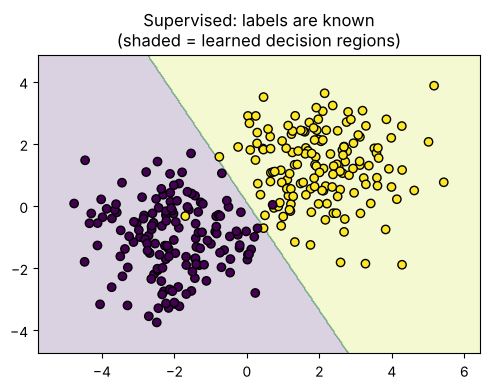

In [2]:
X, y = make_blobs(n_samples=300, centers=[(-2, -1), (2, 1.5)], cluster_std=1.2, random_state=7)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

clf = LogisticRegression().fit(X_train, y_train)
print(f"training accuracy : {clf.score(X_train, y_train):.3f}")
print(f"test accuracy     : {clf.score(X_test, y_test):.3f}")

xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 300),
                     np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 300))
zz = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(5, 4))
plt.contourf(xx, yy, zz, alpha=0.2)
plt.scatter(X[:, 0], X[:, 1], c=y, edgecolor='k')
plt.title('Supervised: labels are known\n(shaded = learned decision regions)')
plt.tight_layout()
plt.savefig('outputs/supervised_classification.png', dpi=110)
plt.show()

**Reading the output.** Because every point came with a label, the model could be *scored*
(accuracy) and corrected. That ability to compare a prediction with the right answer is exactly
what drives learning in the rest of this book.

## 3. Unsupervised learning

**Idea.** There are **no labels**. The algorithm looks for structure in the inputs alone: groups of
similar items (**clustering**), simpler summaries of the data (**dimensionality reduction**), or
unusual items (**anomaly detection**).

A subtle but important point: with no right answers, the model cannot be graded the same way.
Cluster "0", "1", "2" are arbitrary names, and whether the groups are meaningful needs human judgment
or indirect measures.

**Demo.** Three clouds of points. We hide the labels, ask k-means to find 3 groups, and then —
only for the purpose of the demo — peek at the hidden truth to see how well it did.

adjusted Rand index vs. hidden truth: 0.97


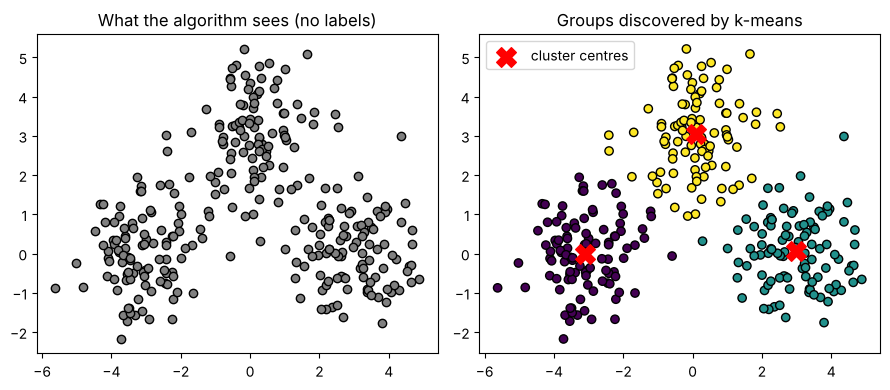

In [3]:
X3, y3_hidden = make_blobs(n_samples=300, centers=[(-3, 0), (0, 3), (3, 0)], cluster_std=0.9, random_state=3)

km = KMeans(n_clusters=3, n_init=10, random_state=0).fit(X3)
print("adjusted Rand index vs. hidden truth:", round(adjusted_rand_score(y3_hidden, km.labels_), 3))

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].scatter(X3[:, 0], X3[:, 1], color='gray', edgecolor='k')
axes[0].set_title('What the algorithm sees (no labels)')
axes[1].scatter(X3[:, 0], X3[:, 1], c=km.labels_, edgecolor='k')
axes[1].scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1], marker='X', s=200, color='red', label='cluster centres')
axes[1].set_title('Groups discovered by k-means'); axes[1].legend()
plt.tight_layout()
plt.savefig('outputs/unsupervised_clustering.png', dpi=110)
plt.show()

**Reading the output.** k-means recovered the three groups from positions alone. Its cluster
numbers need not match the hidden labels (that is why the adjusted Rand index, which ignores naming,
is used to compare).

## 4. Parametric vs non-parametric learning

This second axis is about **how the model stores what it learned**.

- **Parametric model** — a fixed recipe with a **fixed number of adjustable numbers
  (parameters)**, chosen *before* seeing data. Training tunes these numbers; afterwards the training
  data can be thrown away. Model size does not grow with the dataset.
  *Examples: linear regression ($w$ and $b$), neural networks.*
- **Non-parametric model** — **no fixed parameter count**; the model's complexity grows with the data
  (it may literally keep the training examples). *Examples: k-nearest neighbours, kernel methods.*

> Careful: "non-parametric" does not mean "has no parameters at all". It means the number of
> effective parameters is not fixed in advance.

**Demo.** Noisy samples of a sine curve. We fit (a) a straight line (2 parameters), (b) a degree-5
polynomial (6 parameters) — both parametric — and (c) k-nearest-neighbours regression, which keeps all the
training points.

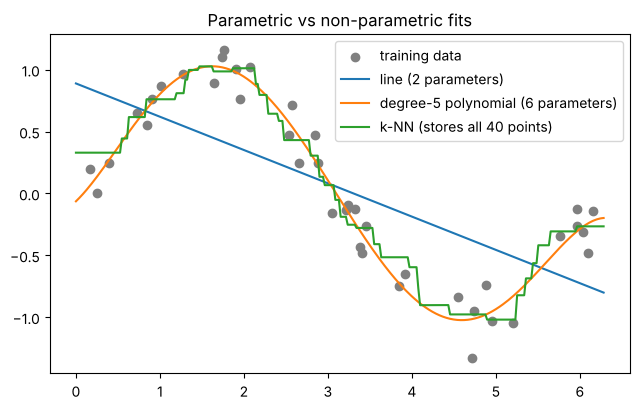

parameters of line  : 2 (unchanged with more data)
parameters of poly5 : 6 (unchanged with more data)
numbers kept by k-NN: 80 (grows with more data: it stores inputs and targets)


In [4]:
rng = np.random.default_rng(1)
x = np.sort(rng.uniform(0, 2 * np.pi, 40))
y = np.sin(x) + rng.normal(0, 0.2, size=x.size)
grid = np.linspace(0, 2 * np.pi, 300)

line = np.polyfit(x, y, deg=1)
poly5 = np.polyfit(x, y, deg=5)
knn = KNeighborsRegressor(n_neighbors=5).fit(x.reshape(-1, 1), y)

plt.figure(figsize=(6.5, 4.2))
plt.scatter(x, y, color='gray', label='training data')
plt.plot(grid, np.polyval(line, grid), label=f'line (2 parameters)')
plt.plot(grid, np.polyval(poly5, grid), label=f'degree-5 polynomial (6 parameters)')
plt.plot(grid, knn.predict(grid.reshape(-1, 1)), label=f'k-NN (stores all {x.size} points)')
plt.legend(); plt.title('Parametric vs non-parametric fits')
plt.tight_layout()
plt.savefig('outputs/parametric_vs_nonparametric.png', dpi=110)
plt.show()

# What happens to model size if we collect 10x more data?
print("parameters of line  :", line.size, "(unchanged with more data)")
print("parameters of poly5 :", poly5.size, "(unchanged with more data)")
print("numbers kept by k-NN:", x.size * 2, "(grows with more data: it stores inputs and targets)")

**Reading the output.** The line is too simple to follow a sine wave (it *underfits*). The polynomial
follows it with only 6 numbers. k-NN follows it too, but only because it carries all the training points
around; with 10× more data its "model" becomes 10× larger. That growth is the signature of a
non-parametric method.

## 5. The 2×2 map of learning methods

The two axes are independent, so every method can be placed in a cell (the placement of some
algorithms is a matter of convention; these are the usual textbook choices):

| | **Parametric** (fixed parameter count) | **Non-parametric** (grows with data) |
|---|---|---|
| **Supervised** (has labels) | linear / logistic regression, **neural networks** | k-nearest neighbours, kernel methods |
| **Unsupervised** (no labels) | k-means (fixed number of centroids), Gaussian mixtures | hierarchical clustering, density-based clustering |

## 6. Why deep learning is mostly *supervised parametric* learning

A neural network is a function with a **fixed, pre-chosen set of weights** (parametric) that is
normally trained on **examples with known answers** (supervised). That is the cell this repository
spends most of its time in. (Unsupervised and self-supervised deep learning also exist, but they
reuse the same parametric machinery.)

## 7. The Predict → Compare → Learn cycle

Supervised parametric learning is a loop of three steps:

1. **Predict** — run the input through the model with its current weights.
2. **Compare** — measure how far the prediction is from the known correct answer (the *error*).
3. **Learn** — nudge the weights in the direction that makes the error smaller.

Repeat many times over many examples. The following chapters take one step each:
**Chapter 3 = Predict**, **Chapter 4 = Compare + Learn** for one weight, **Chapter 5 = Learn with many weights**,
**Chapter 6 = Learn through hidden layers**.

Here is the whole loop in a few lines on the simplest possible model (one weight), purely as a
preview — the reasoning behind the update rule is derived properly in Chapter 4.

In [5]:
x_in, y_true = 2.0, 6.0      # we want a weight w such that w * 2 = 6  ->  w = 3
w = 0.0                      # start with a bad guess
lr = 0.05                    # how big a nudge to apply

for step in range(8):
    prediction = w * x_in                    # 1. Predict
    error = (prediction - y_true) ** 2       # 2. Compare
    w = w - lr * 2 * x_in * (prediction - y_true)   # 3. Learn (rule derived in Chapter 4)
    print(f"step {step}: prediction={prediction:6.3f}  error={error:8.4f}  new w={w:6.3f}")

step 0: prediction= 0.000  error= 36.0000  new w= 1.200
step 1: prediction= 2.400  error= 12.9600  new w= 1.920
step 2: prediction= 3.840  error=  4.6656  new w= 2.352
step 3: prediction= 4.704  error=  1.6796  new w= 2.611
step 4: prediction= 5.222  error=  0.6047  new w= 2.767
step 5: prediction= 5.533  error=  0.2177  new w= 2.860
step 6: prediction= 5.720  error=  0.0784  new w= 2.916
step 7: prediction= 5.832  error=  0.0282  new w= 2.950


## Summary

| Concept | One-line meaning |
|---|---|
| Learning | adjusting internal numbers automatically so outputs improve with experience |
| Supervised | learns from inputs **with** correct answers |
| Unsupervised | finds structure in inputs **without** answers |
| Parametric | fixed number of parameters, independent of data size |
| Non-parametric | complexity grows with the data |
| Predict → Compare → Learn | the basic training loop used by neural networks |